## MCF-7 in co-culture with *Fusobacterium nucleatum* Modeling with MICOM

This script corresponds to the modeling of an MCF-7 community in co-culture with *Fusobacterium nucleatum*. This simulation aims to create a community in which three MCF-7 subpopulations and *F. nucleatum* interact within the same medium, simulating an experimental co-culture such as the one reported in Zhao et al. (2025) work (paper [here](https://onlinelibrary.wiley.com/doi/10.1002/ctm2.70273))

##### import packages

In [29]:
import micom
import pandas as pd
import numpy as np
import osqp
import pickle
import cobra
import cobra.io
import matplotlib.pyplot as plt
import logging
from pathlib import Path
from micom import load_pickle
from micom.media import minimal_medium
from micom.workflows import workflow
from micom import Community

In [2]:
print("MICOM_version:", micom.__version__) #MICOM version 0.37.1

MICOM_version: 0.37.1


---
### **I. Community**

#### **1. Load reconstructions**

The MCF-7 reconstructions were obtained from the work Modeling Cancer Metabolism Heterogeneity with MICOM by Arellano and Resendis (GitHub [here](https://github.com/resendislab/Modeling_Heterogeneity_Cancer_Metabolism_MICOM/tree/main)). In this study, three cellular subpopulations were identified within an MCF-7 spheroid:

Model A – Invasive Population

Model B – Reservoir Population

Model C – Proliferating Population

The *F. nucleatum* reconstruction was obtained from AGORA2 database

In [3]:
A = cobra.io.read_sbml_model('ModelA.xml')
B = cobra.io.read_sbml_model('ModelB.xml')
C = cobra.io.read_sbml_model('ModelC.xml')

In [4]:
F = cobra.io.read_sbml_model('Fusobacterium_nucleatum.xml')

#### **2. Model conditions**

##### **A. Abundance**
**Cancer 50%**
* Population_A (C_A: 4.88%) 
* Population_B (C_B: 19.55%) 
* Population_C (C_C: 22.65%)

**Fusubacterium 50%**
* Fusubacterium (FN: 50% )

##### **B. Oxigen gradients**
* 0.16 mmol/gDW/hr - Normoxia

In [5]:
A2 = A.copy()
A2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(A2, "A_1.xml")

B2 = B.copy()
B2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(B2, "B_1.xml")

C2 = C.copy()
C2.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(C2, "C_1.xml")

In [6]:
FN = F.copy()
FN.reactions.EX_o2_e.lower_bound = -0.16
write_sbml_model(FN, "F_1.xml")

#### **3. Create community**

In [7]:
TyF = {'id': ['CanA', 'CanB', 'CanC','Fusobacterium'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0.50]
    }

df_TyF = pd.DataFrame(data=TyF)
df_TyF

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fusobacterium,F_1.xml,0.50000


In [8]:
TyF = micom.Community (df_TyF, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(TyF.reactions)))

Output()

build a community with a total of 4120 reactions.


#### **4. New medium**

The community growth medium will be modified to a medium composed of: the minimum medium + McCoys 5A

In [9]:
TyF.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

#### **5. Optimize the community**

In [10]:
sol_TyF = TyF.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_TyF

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.050317,0.011181,1126,982
CanB,0.201370,0.044751,742,616
CanC,0.233301,0.051847,1032,807
Fusobacterium,0.515013,0.114456,1029,935
medium,NaN,NaN,191,191


#### **6. Doubling speed**

Once the community has been constructed, the next step is to estimate the doubling times to evaluate whether they are consistent with experimental data.

##### Growth Rate

In [11]:
fluxes = sol_TyF.fluxes
flux_cancer_A_biomass = fluxes.loc['CanA', "biomass_reaction"]
flux_cancer_B_biomass = fluxes.loc['CanB', "biomass_reaction"]
flux_cancer_C_biomass = fluxes.loc['CanC', "biomass_reaction"]
flux_fuso_biomass = fluxes.loc["Fusobacterium", "EX_biomass_e"]

In [12]:
print("Growth Rate of the community:", sol_TyF.growth_rate, "mmol/gDW*hr")
print("Growth Rate of the A:", flux_cancer_A_biomass, "mmol/gDW*hr")
print("Growth Rate of the B:", flux_cancer_B_biomass, "mmol/gDW*hr")
print("Growth Rate of the C:", flux_cancer_C_biomass, "mmol/gDW*hr")
print("Growth Rate of the fusobacterium:", flux_fuso_biomass, "mmol/gDW*hr")

Growth Rate of the community: 0.08061671699670621 mmol/gDW*hr
Growth Rate of the A: 0.011181361924825892 mmol/gDW*hr
Growth Rate of the B: 0.04475132016867521 mmol/gDW*hr
Growth Rate of the C: 0.0518474341961516 mmol/gDW*hr
Growth Rate of the fusobacterium: 0.11445640645564029 mmol/gDW*hr


##### Doubling speed

In [13]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/sol_TyF.growth_rate, "hrs")
print("doubling speed - Cancer A:", r/ flux_cancer_A_biomass, "hrs")
print("doubling speed - Cancer B:", r/ flux_cancer_B_biomass, "hrs")
print("doubling speed - Cancer C:", r/ flux_cancer_C_biomass, "hrs")
print("doubling speed - Fusobacterium:", r/ flux_fuso_biomass, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 8.598057653330953 hrs
doubling speed - Cancer A: 61.991301705470775 hrs
doubling speed - Cancer B: 15.48886553396319 hrs
doubling speed - Cancer C: 13.36897748763418 hrs
doubling speed - Fusobacterium: 6.055992862475438 hrs


---
### **II. Community without *F. nucleatum***

#### **1. Create community**

Next, the simulation will be performed in the absence of *F. nucleatum*, using the same medium. Additionally, reconstructions with normoxic oxygen levels obtained in step I.2 will be used.

In [14]:
Tumor = {'id': ['CanA', 'CanB', 'CanC','Fuso'],
    'file': ["A_1.xml", 'B_1.xml','C_1.xml',"F_1.xml"],
     'abundance': [0.04885,0.1955,0.2265,0] #the abundance for Fusobacterium will be 0.
    }

df_T = pd.DataFrame(data=Tumor)
df_T

,id,file,abundance
0,CanA,A_1.xml,0.04885
1,CanB,B_1.xml,0.19550
2,CanC,C_1.xml,0.22650
3,Fuso,F_1.xml,0.00000


In [15]:
Tumor = micom.Community (df_T, solver = "osqp")
print("build a community with a total of {} reactions.".format(len(Tumor.reactions)))

Output()

build a community with a total of 3017 reactions.


#### **2. Add medium**

In [16]:
Tumor.medium =  {
'EX_ala_L_m':0.7,
'EX_arg_L_m':0.5,  
'EX_asn_L_m':0.7,
'EX_asp_L_m':0.7,
'EX_ca2_m':0.5,
'EX_chol_m':0.7,
'EX_cl_m':0.5, 
'EX_cobalt2_m':0.5, 
'EX_cu2_m':0.5, 
'EX_cys_L_m':0.7,
'EX_fe2_m':0.5, 
'EX_fe3_m':0.5, 
'EX_gal_m':0.01,  
'EX_gln_L_m':0.7,
'EX_his_L_m':0.7,
'EX_ile_L_m':0.7,
'EX_inost_m':0.7,
'EX_k_m':0.5, 
'EX_leu_L_m':0.7,
'EX_lys_L_m':0.5,  
'EX_met_L_m':0.7,
'EX_mg2_m':0.5,  
'EX_mn2_m':0.5,  
'EX_nac_m':0.5,  
'EX_o2_m':0.7,
'EX_h2o_m':0.7,
'EX_phe_L_m':0.5, 
'EX_pi_m':0.5, 
'EX_pnto_R_m':0.5,
'EX_pro_L_m':0.5, 
'EX_ser_L_m':0.7,
'EX_so4_m':0.5, 
'EX_thr_L_m':0.7,
'EX_trp_L_m':0.5, 
'EX_tyr_L_m':0.5,
'EX_val_L_m':0.5,
'EX_zn2_m':0.5, 
'EX_adocbl_m':0.7,
'EX_anth_m':0.7,
'EX_ascb_L_m':0.7,
'EX_btn_m':0.7,
'EX_fol_m':0.7,
'EX_glc_D_m':0.7,
'EX_glu_L_m':0.7,
'EX_gly_m':0.7,
'EX_gthrd_m':0.7,
'EX_na1_m':0.7,
'EX_ncam_m':0.7,
'EX_pydxn_m':0.7,
'EX_ribflv_m':0.7,
'EX_thm_m':0.7
}

#### **3. Optimize the community**

In [17]:
sol_Tumor = Tumor.cooperative_tradeoff(fraction = 0.6, fluxes =True, pfba = True)
sol_Tumor

,abundance,growth_rate,reactions,metabolites
compartments,,,,
CanA,0.103749,0.005211,1126,982
CanB,0.415207,0.020858,742,616
CanC,0.481045,0.026198,1032,807
medium,NaN,NaN,117,117


#### **4. Doubling speed**

##### Growth rate

In [18]:
fluxes = sol_Tumor.fluxes
flux_cancer_A_biomass1 = fluxes.loc['CanA', "biomass_reaction"]
flux_cancer_B_biomass1 = fluxes.loc['CanB', "biomass_reaction"]
flux_cancer_C_biomass1 = fluxes.loc['CanC', "biomass_reaction"]

In [19]:
print("Growth Rate of the community:", sol_Tumor.growth_rate, "mmol/gDW*hr")
print("Growth Rate of the A:", flux_cancer_A_biomass1, "mmol/gDW*hr")
print("Growth Rate of the B:", flux_cancer_B_biomass1, "mmol/gDW*hr")
print("Growth Rate of the C:", flux_cancer_C_biomass1, "mmol/gDW*hr")

Growth Rate of the community: 0.021803117845851476 mmol/gDW*hr
Growth Rate of the A: 0.00521112075381498 mmol/gDW*hr
Growth Rate of the B: 0.02085771065703435 mmol/gDW*hr
Growth Rate of the C: 0.026197582143245433 mmol/gDW*hr


##### Doubling Speed

In [20]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/sol_Tumor.growth_rate, "hrs")
print("doubling speed - Cancer A:", r/ flux_cancer_A_biomass1, "hrs")
print("doubling speed - Cancer B:", r/ flux_cancer_B_biomass1, "hrs")
print("doubling speed - Cancer C:", r/ flux_cancer_C_biomass1, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 31.79119543638259 hrs
doubling speed - Cancer A: 133.01307210210072 hrs
doubling speed - Cancer B: 33.23217931044501 hrs
doubling speed - Cancer C: 26.45844096489113 hrs


---
### **III. Plots**

#### **1. Community with *F. nucleatum***

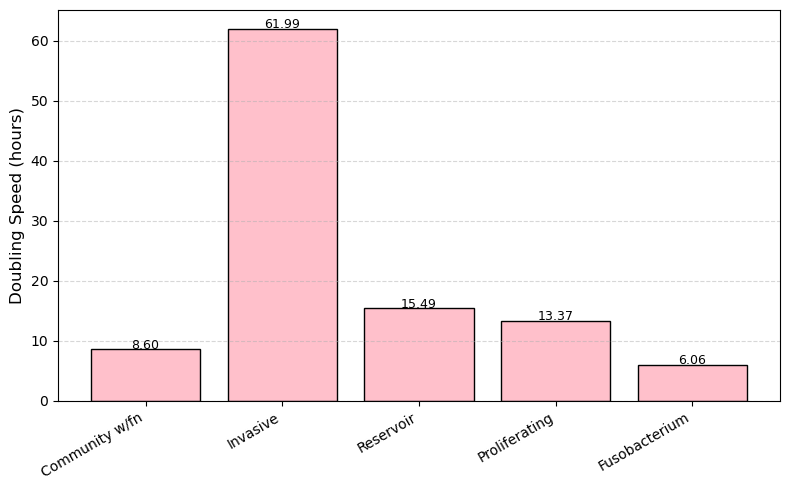

In [21]:
import matplotlib.pyplot as plt


# Calculate the doubling speed (in hours)
doubling_times = {
    "Community w/fn": r / sol_TyF.growth_rate,
    "Invasive": r / flux_cancer_A_biomass,
    "Reservoir": r / flux_cancer_B_biomass,
    "Proliferating": r / flux_cancer_C_biomass,
    "Fusobacterium": r / flux_fuso_biomass
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

# Create the graph
plt.figure(figsize=(8,5))
plt.bar(labels, values, color="pink", edgecolor="black")

# 
plt.ylabel("Doubling Speed (hours)", fontsize=12)
#plt.title("Doubling Speed - Community, Cancer, Fusobacterium", fontsize=13)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
#
for i, v in enumerate(values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

#### **2. Community without *F. nucleatum***

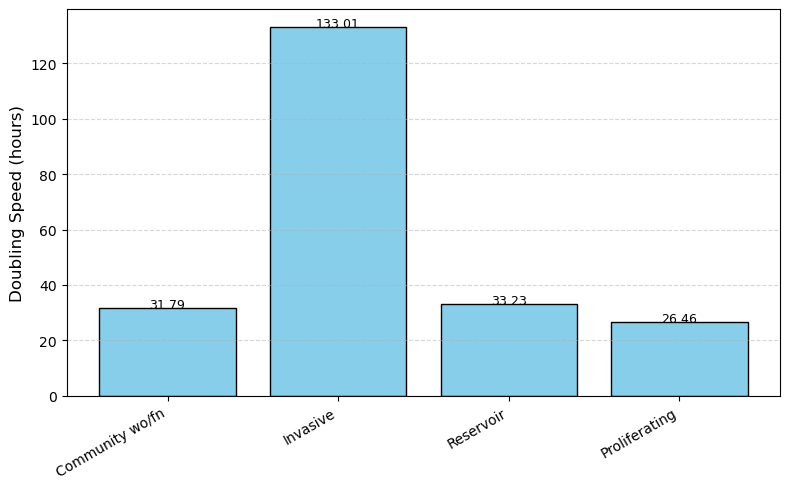

In [22]:
import matplotlib.pyplot as plt


# Calculate the doubling speed (in hours)
doubling_times = {
    "Community wo/fn": r / sol_Tumor.growth_rate,
    "Invasive": r / flux_cancer_A_biomass1,
    "Reservoir": r / flux_cancer_B_biomass1,
    "Proliferating": r / flux_cancer_C_biomass1,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

# Create the graph
plt.figure(figsize=(8,5))
plt.bar(labels, values, color="skyblue", edgecolor="black")

# 
plt.ylabel("Doubling Speed (hours)", fontsize=12)
#plt.title("Doubling Speed - Community, Cancer, Fusobacterium", fontsize=13)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 
for i, v in enumerate(values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

#### **3. Doubling Speed Comparison Between Communities**

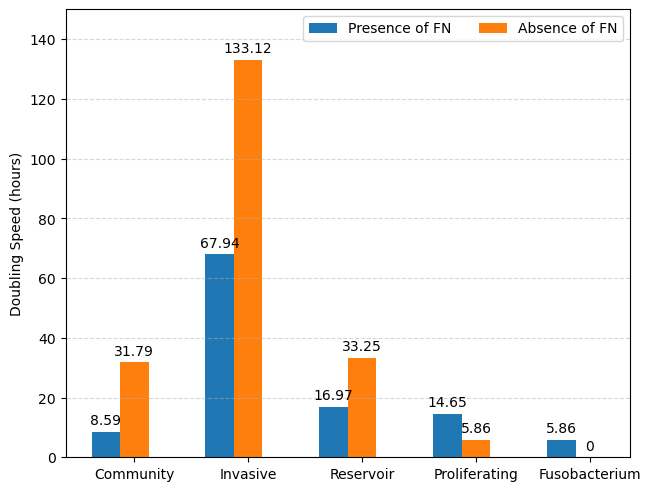

<Figure size 1600x1000 with 0 Axes>

In [34]:
import matplotlib.pyplot as plt
import numpy as np

population = ("Community", "Invasive", "Reservoir", "Proliferating", "Fusobacterium")
penguin_means = {
    'Presence of FN': (8.59, 67.94, 16.97,14.65,5.86),
    'Absence of FN': (31.79, 133.12, 33.25,5.86,0),
}

x = np.arange(len(population))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in penguin_means.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

plt.figure(figsize=(16,10))
# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Doubling Speed (hours)')
#ax.set_title('Penguin attributes by species')
ax.set_xticks(x + width, population)
ax.legend(loc='upper right', ncols=2)
ax.set_ylim(0, 150)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

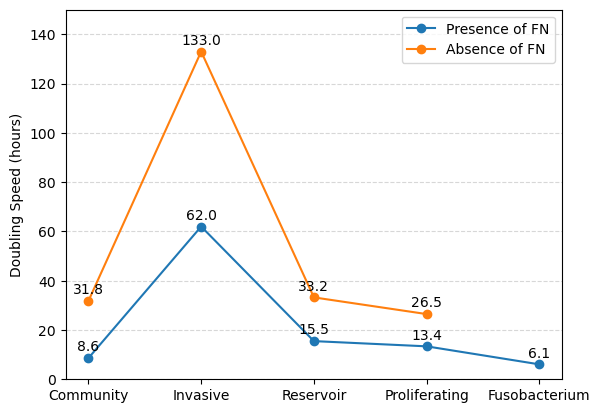

In [35]:
doubling_times = {
    "Community": r / sol_TyF.growth_rate,
    "Invasive": r / flux_cancer_A_biomass,
    "Reservoir": r / flux_cancer_B_biomass,
    "Proliferating": r / flux_cancer_C_biomass,
    "Fusobacterium": r / flux_fuso_biomass
}

doubling_times1 = {
    "Community": r / sol_Tumor.growth_rate,
    "Invasive": r / flux_cancer_A_biomass1,
    "Reservoir": r / flux_cancer_B_biomass1,
    "Proliferating": r / flux_cancer_C_biomass1,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

labels1 = list(doubling_times1.keys())
values1 = list(doubling_times1.values())


fig, ax = plt.subplots()
ax.plot(labels, values, label="Presence of FN",marker='o')
ax.plot(labels1, values1, label="Absence of FN",marker='o')

for x, y in zip(labels, values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

for x, y in zip(labels1, values1):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()
ax.set_ylim(0, 150)
ax.set_ylabel('Doubling Speed (hours)')
plt.savefig("plots/tiempo_duplicacion.png", dpi=300, bbox_inches="tight")
plt.show()


In [1]:
import math
r = math.log(2)

print("Community Cancer y Fusobacterium:")
print("doubling speed - Community:", r/0.0447, "hrs")

Community Cancer y Fusobacterium:
doubling speed - Community: 15.506648334674392 hrs


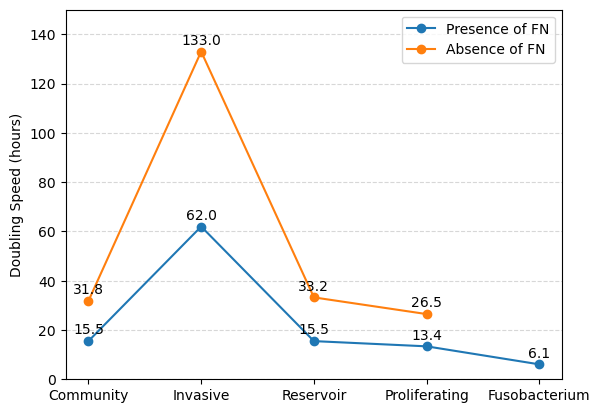

In [4]:
import matplotlib.pyplot as plt
import numpy as np
doubling_times = {
    "Community": 15.506648334674392,
    "Invasive": 61.991301705470775,
    "Reservoir": 15.48886553396319,
    "Proliferating": 13.36897748763418,
    "Fusobacterium": 6.055992862475438
}

doubling_times1 = {
    "Community": 31.79119543638259,
    "Invasive": 133.01307210210072,
    "Reservoir": 33.23217931044501,
    "Proliferating": 26.45844096489113,
}

# Extract names and values
labels = list(doubling_times.keys())
values = list(doubling_times.values())

labels1 = list(doubling_times1.keys())
values1 = list(doubling_times1.values())


fig, ax = plt.subplots()
ax.plot(labels, values, label="Presence of FN",marker='o')
ax.plot(labels1, values1, label="Absence of FN",marker='o')

for x, y in zip(labels, values):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

for x, y in zip(labels1, values1):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0,5), ha='center')

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()
ax.set_ylim(0, 150)
ax.set_ylabel('Doubling Speed (hours)')
plt.savefig("plots/tiempo_duplicacion_new.png", dpi=300, bbox_inches="tight")
plt.show()

### **IV. Save to CSV files**

In [28]:
fluxesTyF = sol_TyF.fluxes
fluxesTyF.to_csv('TyF.csv')